In [1]:

from pathlib import Path
import random
import numpy as np
import torch
import timm

# 1. Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# 2. Project locations
DATA_DIR = Path.cwd()

SPLIT_FILE = DATA_DIR / "dataset_split.csv"

MODEL_NAME = "deit_tiny_patch16_224.fb_in1k"

BASELINE_CHECKPOINT = (
    DATA_DIR
    / "results"
    / "deit_tiny"
    / "checkpoints"
    / "deit_tiny_best.pth"
)

# 3. New results folder
RESULTS_DIR = DATA_DIR / "results" / "deit_tiny_finetune"

CHECKPOINT_DIR = RESULTS_DIR / "checkpoints"
PLOTS_DIR = RESULTS_DIR / "plots"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# 4. Device
DEVICE = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cpu"
)

# 5. Verify files
assert SPLIT_FILE.exists(), "Dataset split not found"
assert BASELINE_CHECKPOINT.exists(), "Baseline checkpoint not found"

# 6. Rebuild architecture without redownloading weights
model = timm.create_model(
    MODEL_NAME,
    pretrained=False,
    num_classes=3
)

# 7. Load best head-only checkpoint
checkpoint = torch.load(
    BASELINE_CHECKPOINT,
    map_location="cpu",
    weights_only=True
)

assert checkpoint["model_name"] == MODEL_NAME

model.load_state_dict(
    checkpoint["model_state_dict"]
)

print("Loaded baseline checkpoint")
print("Baseline epoch:", checkpoint["epoch"])
print(
    "Baseline Macro-F1:",
    round(checkpoint["val_macro_f1"], 4)
)

# 8. Freeze entire model
for param in model.parameters():
    param.requires_grad = False

# 9. Unfreeze LAST TWO transformer blocks
for block in model.blocks[-2:]:
    for param in block.parameters():
        param.requires_grad = True

# 10. Unfreeze classification head
for param in model.head.parameters():
    param.requires_grad = True

# 11. Move model to GPU
model = model.to(DEVICE)
model.eval()

# 12. Count parameters
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\nDEiT-TINY FINE-TUNING CONFIGURATION")
print("-" * 48)

print("Device:", DEVICE)
print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")
print("Frozen parameters:", f"{total_params - trainable_params:,}")

print("\nTrainable transformer blocks:")
for i, block in enumerate(model.blocks):
    if any(p.requires_grad for p in block.parameters()):
        print(f"  Block {i + 1}")

print("\nClassification head trainable:",
      all(p.requires_grad for p in model.head.parameters()))

print("\nResults folder:", RESULTS_DIR)
print("\nSetup complete!")


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loaded baseline checkpoint
Baseline epoch: 5
Baseline Macro-F1: 0.8873

DEiT-TINY FINE-TUNING CONFIGURATION
------------------------------------------------
Device: mps
Total parameters: 5,524,995
Trainable parameters: 890,307
Frozen parameters: 4,634,688

Trainable transformer blocks:
  Block 11
  Block 12

Classification head trainable: True

Results folder: /Users/pooja/Documents/Academic Projects/Deep Learning Projects/Warmup Project/SEM Image Database/results/deit_tiny_finetune

Setup complete!


In [2]:

import csv
from collections import Counter
from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

# 1. Class mapping — identical to original experiment
CLASSES = ["Brittle", "Ductile", "Mixed"]

class_to_idx = {
    "Brittle": 0,
    "Ductile": 1,
    "Mixed": 2
}

assert checkpoint["class_to_idx"] == class_to_idx, (
    "Class mapping differs from baseline checkpoint!"
)

# 2. Read the original saved dataset split
with open(SPLIT_FILE, "r", encoding="utf-8-sig") as f:
    split_records = list(csv.DictReader(f))

train_records = [
    row for row in split_records
    if row["split"] == "train"
]

val_records = [
    row for row in split_records
    if row["split"] == "validation"
]

test_records = [
    row for row in split_records
    if row["split"] == "test"
]

# 3. Identical ImageNet normalization
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# 4. Dataset class
class SEMDataset(Dataset):

    def __init__(self, records, data_dir, transform):
        self.records = records
        self.data_dir = data_dir
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        row = self.records[idx]

        image_path = (
            self.data_dir / row["label"] / row["filename"]
        )

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        image = self.transform(image)
        label = class_to_idx[row["label"]]

        return image, label

# 5. Create datasets
train_dataset = SEMDataset(
    train_records, DATA_DIR, train_transform
)

val_dataset = SEMDataset(
    val_records, DATA_DIR, eval_transform
)

test_dataset = SEMDataset(
    test_records, DATA_DIR, eval_transform
)

# 6. Create DataLoaders
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# Deliberately do not evaluate the test set.
# We'll use it after model selection.

# 7. Verify datasets
train_counts = Counter(
    row["label"] for row in train_records
)

print("DATASET VERIFICATION")
print("-" * 45)

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test (reserved):", len(test_dataset))

print("\nTraining class distribution:")
for cls in CLASSES:
    print(f"  {cls}: {train_counts[cls]}")

print("\nBatches:")
print("  Training:", len(train_loader))
print("  Validation:", len(val_loader))

images, labels = next(iter(train_loader))

print("\nSample image batch:", images.shape)
print("Sample label batch:", labels.shape)

assert len(train_dataset) == 1402
assert len(val_dataset) == 280
assert len(test_dataset) == 279
assert images.shape[1:] == (3, 224, 224)

print("\nDataset setup successful!")


DATASET VERIFICATION
---------------------------------------------
Training: 1402
Validation: 280
Test (reserved): 279

Training class distribution:
  Brittle: 589
  Ductile: 711
  Mixed: 102

Batches:
  Training: 88
  Validation: 18

Sample image batch: torch.Size([16, 3, 224, 224])
Sample label batch: torch.Size([16])

Dataset setup successful!


In [3]:

import torch.nn as nn

# 1. Calculate class weights
num_samples = len(train_records)
num_classes = len(CLASSES)

class_weights = torch.tensor(
    [
        num_samples / (num_classes * train_counts[cls])
        for cls in CLASSES
    ],
    dtype=torch.float32,
    device=DEVICE
)

# 2. Weighted cross-entropy loss
criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

# 3. Differential learning rates
TRANSFORMER_LR = 1e-5
HEAD_LR = 1e-4
WEIGHT_DECAY = 1e-4

# 4. Optimizer with separate parameter groups
optimizer = torch.optim.AdamW(
    [
        {
            "params": [
                p
                for block in model.blocks[-2:]
                for p in block.parameters()
            ],
            "lr": TRANSFORMER_LR
        },
        {
            "params": model.head.parameters(),
            "lr": HEAD_LR
        }
    ],
    weight_decay=WEIGHT_DECAY
)

# 5. Keep pretrained stochastic layers inactive
# Gradients still flow through trainable blocks.
model.eval()

# 6. Verify parameter configuration
block_params = sum(
    p.numel()
    for block in model.blocks[-2:]
    for p in block.parameters()
)

head_params = sum(
    p.numel()
    for p in model.head.parameters()
)

optimized_params = sum(
    p.numel()
    for group in optimizer.param_groups
    for p in group["params"]
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

assert optimized_params == trainable_params
assert trainable_params == 890307

# 7. Print configuration
print("DEiT-TINY FINE-TUNING OPTIMIZER")
print("-" * 50)

print("\nCLASS WEIGHTS")
for cls, weight in zip(CLASSES, class_weights):
    print(f"{cls}: {weight.item():.4f}")

print("\nTRAINABLE COMPONENTS")
print(f"Last two transformer blocks: {block_params:,}")
print(f"Classification head:        {head_params:,}")
print(f"Total optimized parameters: {optimized_params:,}")

print("\nLEARNING RATES")
print(f"Transformer blocks: {TRANSFORMER_LR}")
print(f"Classification head: {HEAD_LR}")

print("\nOptimizer:", optimizer.__class__.__name__)
print("Weight decay:", WEIGHT_DECAY)
print("Loss:", criterion)

print("\nConfiguration verified!")


DEiT-TINY FINE-TUNING OPTIMIZER
--------------------------------------------------

CLASS WEIGHTS
Brittle: 0.7934
Ductile: 0.6573
Mixed: 4.5817

TRAINABLE COMPONENTS
Last two transformer blocks: 889,728
Classification head:        579
Total optimized parameters: 890,307

LEARNING RATES
Transformer blocks: 1e-05
Classification head: 0.0001

Optimizer: AdamW
Weight decay: 0.0001
Loss: CrossEntropyLoss()

Configuration verified!


In [4]:

import time
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score
)

# 1. Training configuration
MAX_EPOCHS = 10
PATIENCE = 4

history_ft = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_macro_f1": [],
    "val_mixed_recall": [],
    "epoch_time": []
}

# Starting benchmark: previous best head-only checkpoint
baseline_f1 = float(checkpoint["val_macro_f1"])

best_f1 = baseline_f1
best_epoch = 0
epochs_without_improvement = 0

checkpoint_path = (
    CHECKPOINT_DIR / "deit_tiny_finetuned_best.pth"
)

# 2. Save the initial checkpoint as a fallback
def save_checkpoint(epoch, macro_f1):
    torch.save({
        "model_state_dict": {
            k: v.detach().cpu().clone()
            for k, v in model.state_dict().items()
        },
        "epoch": epoch,
        "val_macro_f1": macro_f1,
        "class_to_idx": class_to_idx,
        "model_name": MODEL_NAME,
        "experiment": "last_two_blocks_finetuning"
    }, checkpoint_path)

save_checkpoint(epoch=0, macro_f1=baseline_f1)

print("FINE-TUNING DeiT-Tiny")
print("-" * 65)
print(f"Starting Macro-F1: {baseline_f1:.4f}")
print(f"Maximum epochs: {MAX_EPOCHS}")
print(f"Early stopping patience: {PATIENCE}")
print()

# 3. Training loop
for epoch in range(MAX_EPOCHS):

    start_time = time.perf_counter()

    # Keep stochastic layers inactive.
    # Gradients still flow through unfrozen blocks.
    model.eval()

    train_loss_total = 0.0
    train_samples = 0

    for images, labels in train_loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        # Forward pass
        outputs = model(images)

        # Weighted cross-entropy
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update the last 2 blocks and head
        optimizer.step()

        train_loss_total += loss.item() * labels.size(0)
        train_samples += labels.size(0)

    train_loss = train_loss_total / train_samples

    # 4. Validation
    model.eval()

    val_loss_total = 0.0
    val_samples = 0

    all_labels = []
    all_predictions = []

    with torch.inference_mode():

        for images, labels in val_loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_total += (
                loss.item() * labels.size(0)
            )
            val_samples += labels.size(0)

            predictions = outputs.argmax(dim=1)

            all_labels.extend(
                labels.cpu().tolist()
            )

            all_predictions.extend(
                predictions.cpu().tolist()
            )

    val_loss = val_loss_total / val_samples

    # 5. Validation metrics
    val_accuracy = accuracy_score(
        all_labels, all_predictions
    )

    val_macro_f1 = f1_score(
        all_labels,
        all_predictions,
        labels=[0, 1, 2],
        average="macro",
        zero_division=0
    )

    val_mixed_recall = recall_score(
        all_labels,
        all_predictions,
        labels=[2],
        average="macro",
        zero_division=0
    )

    # Synchronize MPS for more accurate timing
    if DEVICE.type == "mps":
        torch.mps.synchronize()

    elapsed = time.perf_counter() - start_time

    # 6. Record history
    history_ft["train_loss"].append(train_loss)
    history_ft["val_loss"].append(val_loss)
    history_ft["val_accuracy"].append(val_accuracy)
    history_ft["val_macro_f1"].append(val_macro_f1)
    history_ft["val_mixed_recall"].append(val_mixed_recall)
    history_ft["epoch_time"].append(elapsed)

    # 7. Save best model
    if val_macro_f1 > best_f1 + 1e-6:

        best_f1 = val_macro_f1
        best_epoch = epoch + 1

        save_checkpoint(
            epoch=best_epoch,
            macro_f1=best_f1
        )

        epochs_without_improvement = 0
        status = "NEW BEST"

    else:

        epochs_without_improvement += 1
        status = "No improvement"

    # 8. Print epoch results
    print(
        f"Epoch {epoch+1:02d}/{MAX_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Accuracy: {val_accuracy:.3f} | "
        f"Macro-F1: {val_macro_f1:.4f} | "
        f"Mixed Recall: {val_mixed_recall:.3f} | "
        f"Time: {elapsed:.1f}s | "
        f"{status}"
    )

    # 9. Early stopping
    if epochs_without_improvement >= PATIENCE:
        print("\nEarly stopping triggered.")
        break

# 10. Restore best model
best_checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

model = model.to(DEVICE)
model.eval()

# 11. Final summary
print("\nFINE-TUNING COMPLETED")
print("-" * 65)

print("Best fine-tuning epoch:", best_epoch)

print(f"Original DeiT-Tiny Macro-F1: {baseline_f1:.4f}")
print(f"Fine-tuned DeiT-Tiny F1:     {best_f1:.4f}")
print(f"Improvement:                {best_f1 - baseline_f1:+.4f}")

print("\nREFERENCE MODELS")
print("ResNet-18 head-only:   0.9434")
print("ResNet-18 fine-tuned:  0.9525")

print(
    "\nAverage epoch time:",
    f"{np.mean(history_ft['epoch_time']):.1f}s"
)

print("\nCheckpoint saved:", checkpoint_path)


FINE-TUNING DeiT-Tiny
-----------------------------------------------------------------
Starting Macro-F1: 0.8873
Maximum epochs: 10
Early stopping patience: 4

Epoch 01/10 | Train Loss: 0.2282 | Val Loss: 0.1538 | Accuracy: 0.950 | Macro-F1: 0.8849 | Mixed Recall: 0.762 | Time: 9.2s | No improvement
Epoch 02/10 | Train Loss: 0.2100 | Val Loss: 0.1585 | Accuracy: 0.950 | Macro-F1: 0.8849 | Mixed Recall: 0.762 | Time: 7.0s | No improvement
Epoch 03/10 | Train Loss: 0.1977 | Val Loss: 0.1354 | Accuracy: 0.954 | Macro-F1: 0.8915 | Mixed Recall: 0.762 | Time: 6.7s | NEW BEST
Epoch 04/10 | Train Loss: 0.1934 | Val Loss: 0.1571 | Accuracy: 0.943 | Macro-F1: 0.8721 | Mixed Recall: 0.762 | Time: 6.6s | No improvement
Epoch 05/10 | Train Loss: 0.1767 | Val Loss: 0.1445 | Accuracy: 0.950 | Macro-F1: 0.8849 | Mixed Recall: 0.762 | Time: 6.4s | No improvement
Epoch 06/10 | Train Loss: 0.1929 | Val Loss: 0.1450 | Accuracy: 0.946 | Macro-F1: 0.8783 | Mixed Recall: 0.762 | Time: 6.5s | No improvement


Original DeiT-Tiny
              precision    recall  f1-score   support

     Brittle     0.9669    1.0000    0.9832       117
     Ductile     0.9783    0.9507    0.9643       142
       Mixed     0.7143    0.7143    0.7143        21

    accuracy                         0.9536       280
   macro avg     0.8865    0.8883    0.8873       280
weighted avg     0.9537    0.9536    0.9534       280


Fine-tuned DeiT-Tiny
              precision    recall  f1-score   support

     Brittle     0.9748    0.9915    0.9831       117
     Ductile     0.9853    0.9437    0.9640       142
       Mixed     0.6800    0.8095    0.7391        21

    accuracy                         0.9536       280
   macro avg     0.8800    0.9149    0.8954       280
weighted avg     0.9580    0.9536    0.9551       280



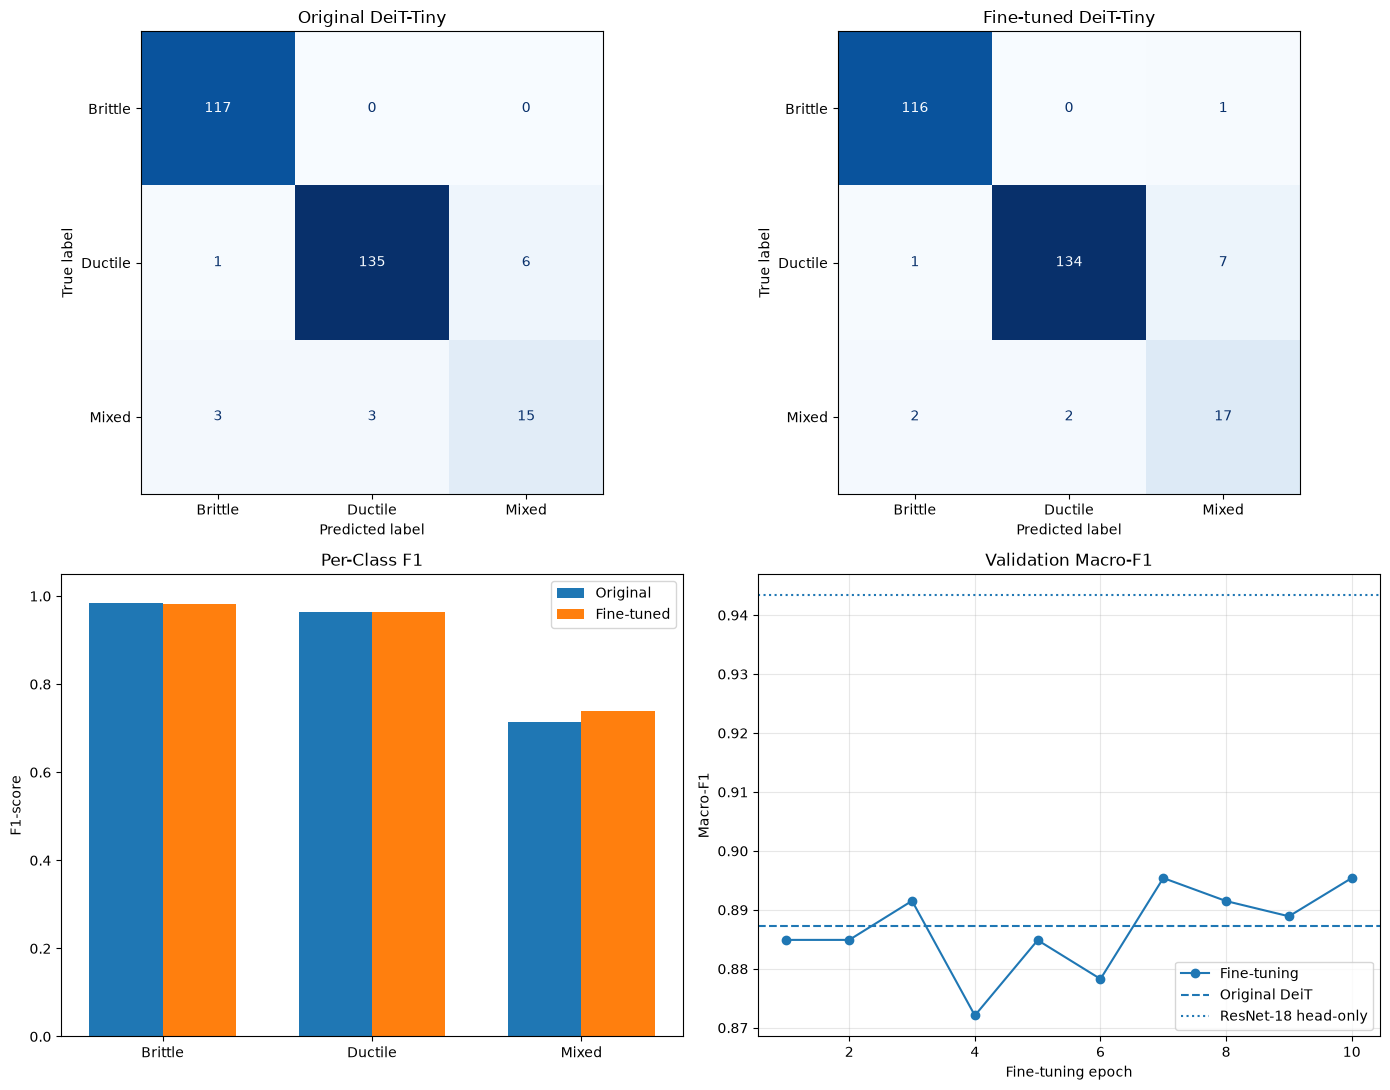


PREDICTION CHANGES
-------------------------------------------------------
Corrected errors: 2
New errors: 2
Changed but still incorrect: 0

CHANGED IMAGES
304_H2_04_9.png | Actual: Mixed | Before: Brittle | After: Mixed
mX65_H2_29_23.png | Actual: Mixed | Before: Ductile | After: Mixed
304_H2_02_23.png | Actual: Brittle | Before: Brittle | After: Mixed
316L_AR_04_21.png | Actual: Ductile | Before: Ductile | After: Mixed

Plot saved: /Users/pooja/Documents/Academic Projects/Deep Learning Projects/Warmup Project/SEM Image Database/results/deit_tiny_finetune/plots/deit_finetuning_comparison.png


In [5]:

import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    f1_score
)

# 1. Reconstruct original head-only DeiT
baseline_model = timm.create_model(
    MODEL_NAME,
    pretrained=False,
    num_classes=3
)

baseline_model.load_state_dict(
    checkpoint["model_state_dict"]
)

baseline_model = baseline_model.to(DEVICE)
baseline_model.eval()

# Fine-tuned best checkpoint is already loaded
model.eval()

# 2. Evaluate both on identical validation images
def get_predictions(net, loader):
    actual = []
    predicted = []

    with torch.inference_mode():
        for images, labels in loader:
            outputs = net(images.to(DEVICE))
            preds = outputs.argmax(dim=1)

            actual.extend(labels.tolist())
            predicted.extend(preds.cpu().tolist())

    return actual, predicted


y_true, baseline_preds = get_predictions(
    baseline_model, val_loader
)

y_true_ft, finetuned_preds = get_predictions(
    model, val_loader
)

assert y_true == y_true_ft
assert len(y_true) == len(val_records)

# 3. Print classification reports
for name, predictions in [
    ("Original DeiT-Tiny", baseline_preds),
    ("Fine-tuned DeiT-Tiny", finetuned_preds)
]:
    print("\n" + name)
    print("=" * 55)

    print(classification_report(
        y_true,
        predictions,
        labels=[0, 1, 2],
        target_names=CLASSES,
        digits=4,
        zero_division=0
    ))

# 4. Compare per-class F1
baseline_f1_classes = f1_score(
    y_true, baseline_preds,
    labels=[0, 1, 2],
    average=None
)

finetuned_f1_classes = f1_score(
    y_true, finetuned_preds,
    labels=[0, 1, 2],
    average=None
)

# 5. Create plots
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

# Original confusion matrix
cm_before = confusion_matrix(
    y_true, baseline_preds, labels=[0, 1, 2]
)

ConfusionMatrixDisplay(
    cm_before, display_labels=CLASSES
).plot(
    ax=axes[0, 0],
    cmap="Blues",
    colorbar=False
)

axes[0, 0].set_title("Original DeiT-Tiny")

# Fine-tuned confusion matrix
cm_after = confusion_matrix(
    y_true, finetuned_preds, labels=[0, 1, 2]
)

ConfusionMatrixDisplay(
    cm_after, display_labels=CLASSES
).plot(
    ax=axes[0, 1],
    cmap="Blues",
    colorbar=False
)

axes[0, 1].set_title("Fine-tuned DeiT-Tiny")

# Per-class F1 comparison
x = np.arange(len(CLASSES))
width = 0.35

axes[1, 0].bar(
    x - width / 2,
    baseline_f1_classes,
    width,
    label="Original"
)

axes[1, 0].bar(
    x + width / 2,
    finetuned_f1_classes,
    width,
    label="Fine-tuned"
)

axes[1, 0].set_xticks(x)
axes[1, 0].set_xticklabels(CLASSES)
axes[1, 0].set_ylim(0, 1.05)
axes[1, 0].set_ylabel("F1-score")
axes[1, 0].set_title("Per-Class F1")
axes[1, 0].legend()

# Fine-tuning macro-F1 history
epochs = np.arange(
    1, len(history_ft["val_macro_f1"]) + 1
)

axes[1, 1].plot(
    epochs,
    history_ft["val_macro_f1"],
    marker="o",
    label="Fine-tuning"
)

axes[1, 1].axhline(
    float(checkpoint["val_macro_f1"]),
    linestyle="--",
    label="Original DeiT"
)

axes[1, 1].axhline(
    0.9434,
    linestyle=":",
    label="ResNet-18 head-only"
)

axes[1, 1].set_title("Validation Macro-F1")
axes[1, 1].set_xlabel("Fine-tuning epoch")
axes[1, 1].set_ylabel("Macro-F1")
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()

plot_path = (
    PLOTS_DIR / "deit_finetuning_comparison.png"
)

plt.savefig(
    plot_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# 6. Identify changed predictions
corrected = []
new_errors = []
other_changes = []

for i, (actual, before, after) in enumerate(
    zip(y_true, baseline_preds, finetuned_preds)
):
    if before == after:
        continue

    if before != actual and after == actual:
        corrected.append(i)
    elif before == actual and after != actual:
        new_errors.append(i)
    else:
        other_changes.append(i)

print("\nPREDICTION CHANGES")
print("-" * 55)

print("Corrected errors:", len(corrected))
print("New errors:", len(new_errors))
print("Changed but still incorrect:", len(other_changes))

print("\nCHANGED IMAGES")

for i in corrected + new_errors + other_changes:
    print(
        f"{val_records[i]['filename']} | "
        f"Actual: {CLASSES[y_true[i]]} | "
        f"Before: {CLASSES[baseline_preds[i]]} | "
        f"After: {CLASSES[finetuned_preds[i]]}"
    )

print("\nPlot saved:", plot_path)


In [6]:

import json
import numpy as np
from datetime import datetime, timezone
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# 1. Helper to make NumPy values JSON-compatible
def json_safe(value):
    if isinstance(value, dict):
        return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(v) for v in value]
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.generic):
        return value.item()
    return value

# 2. Calculate metrics from actual predictions
def model_metrics(actual, predictions):
    return {
        "accuracy": accuracy_score(actual, predictions),
        "macro_f1": f1_score(
            actual, predictions,
            average="macro",
            zero_division=0
        ),
        "classification_report": classification_report(
            actual, predictions,
            labels=[0, 1, 2],
            target_names=CLASSES,
            output_dict=True,
            zero_division=0
        ),
        "confusion_matrix": confusion_matrix(
            actual, predictions,
            labels=[0, 1, 2]
        ).tolist()
    }

baseline_metrics = model_metrics(
    y_true, baseline_preds
)

finetuned_metrics = model_metrics(
    y_true, finetuned_preds
)

# 3. Record changed predictions
prediction_changes = []

for i, (actual, before, after) in enumerate(
    zip(y_true, baseline_preds, finetuned_preds)
):
    if before == after:
        continue

    if before != actual and after == actual:
        status = "corrected"
    elif before == actual and after != actual:
        status = "new_error"
    else:
        status = "changed_still_wrong"

    prediction_changes.append({
        "filename": val_records[i]["filename"],
        "actual": CLASSES[actual],
        "before": CLASSES[before],
        "after": CLASSES[after],
        "status": status
    })

# 4. Build complete experiment summary
summary = {
    "experiment": "DeiT-Tiny SEM Fracture Classification",
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "architecture": {
        "name": MODEL_NAME,
        "type": "Vision Transformer",
        "total_parameters": sum(
            p.numel() for p in model.parameters()
        ),
        "fine_tuning_trainable_parameters": sum(
            p.numel() for p in model.parameters()
            if p.requires_grad
        ),
        "fine_tuned_blocks": [11, 12],
        "patch_size": 16,
        "pretraining": "ImageNet-1K"
    },

    "dataset": {
        "source": "SEM Image Database",
        "split_file": "dataset_split.csv",
        "train": len(train_records),
        "validation": len(val_records),
        "test_reserved": len(test_records),
        "classes": CLASSES,
        "training_class_counts": dict(train_counts),
        "input_size": [224, 224],
        "batch_size": BATCH_SIZE
    },

    "fine_tuning_configuration": {
        "initial_checkpoint": str(BASELINE_CHECKPOINT),
        "transformer_learning_rate": TRANSFORMER_LR,
        "head_learning_rate": HEAD_LR,
        "weight_decay": WEIGHT_DECAY,
        "optimizer": "AdamW",
        "loss": "Class-weighted CrossEntropyLoss",
        "class_weights": class_weights.cpu().tolist(),
        "maximum_epochs": MAX_EPOCHS,
        "early_stopping_patience": PATIENCE,
        "epochs_completed": len(history_ft["train_loss"]),
        "best_epoch": int(best_checkpoint["epoch"]),
        "best_checkpoint": str(checkpoint_path)
    },

    "head_only": {
        "best_epoch": int(checkpoint["epoch"]),
        **baseline_metrics
    },

    "fine_tuned": {
        **finetuned_metrics
    },

    "comparison": {
        "macro_f1_improvement": (
            finetuned_metrics["macro_f1"]
            - baseline_metrics["macro_f1"]
        ),
        "accuracy_improvement": (
            finetuned_metrics["accuracy"]
            - baseline_metrics["accuracy"]
        ),
        "corrected_errors": len(corrected),
        "new_errors": len(new_errors),
        "other_prediction_changes": len(other_changes),
        "changed_images": prediction_changes
    },

    "training_history": history_ft,

    "reference_models": {
        "resnet18_head_only_macro_f1": 0.9434,
        "resnet18_finetuned_macro_f1": 0.9525
    },

    "limitations": [
        "Results use the validation set, not the test set.",
        "Filename-based grouping does not prove physical specimen independence.",
        "The Mixed validation class contains only 21 images.",
        "Only the last two transformer blocks were fine-tuned.",
        "Single-seed results; no repeated-run uncertainty estimate."
    ],

    "test_evaluated": False
}

# 5. Save JSON
summary_path = RESULTS_DIR / "experiment_summary.json"

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(json_safe(summary), f, indent=4)

# 6. Verify saved file
with open(summary_path, "r", encoding="utf-8") as f:
    saved_summary = json.load(f)

assert saved_summary["test_evaluated"] is False

print("DEiT-TINY EXPERIMENT SUMMARY SAVED")
print("-" * 55)

print("Head-only Macro-F1:",
      f"{baseline_metrics['macro_f1']:.4f}")

print("Fine-tuned Macro-F1:",
      f"{finetuned_metrics['macro_f1']:.4f}")

print("Improvement:",
      f"{summary['comparison']['macro_f1_improvement']:+.4f}")

print("\nCorrected:", len(corrected))
print("New errors:", len(new_errors))

print("\nJSON saved to:")
print(summary_path)

print("\nVerification successful!")


DEiT-TINY EXPERIMENT SUMMARY SAVED
-------------------------------------------------------
Head-only Macro-F1: 0.8873
Fine-tuned Macro-F1: 0.8954
Improvement: +0.0081

Corrected: 2
New errors: 2

JSON saved to:
/Users/pooja/Documents/Academic Projects/Deep Learning Projects/Warmup Project/SEM Image Database/results/deit_tiny_finetune/experiment_summary.json

Verification successful!
